# L4 综合实验｜防泄漏统计建模

本实验整合第 47–50 课：历史技术特征 → 厚尾风险诊断 → 因子归因 → 时间序列机器学习 → 延迟信号和成本后回测。

- 环境：`pkm-quant`
- 数据：固定模拟行情及由其构造的因子；非真实证券
- 输出：`outputs/L4_model_metrics.csv`、`L4_oof_nav.png`

## 1. 验收原则

1. 所有滚动特征只使用当时及以前数据；
2. 标签明确指向下一日；
3. TimeSeriesSplit 中训练结束早于测试开始；
4. 模型预测只在样本外日期评价；
5. 持仓使用上一期预测并扣除换手成本；
6. 收益同时报告厚尾分位数和因子归因。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


In [2]:
# 导入统计、因子回归和机器学习工具。
from scipy import stats
import statsmodels.api as sm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score

## 2. 构造无未来信息的研究表

技术特征在 t 日收盘后已知，`next_return` 属于 t+1 日标签。删掉 NaN 后仍要保留日期顺序。

In [3]:
# 从模拟价格生成技术特征和下一日标签。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
prices = daily.pivot(index="date", columns="symbol", values="adj_close").sort_index()
asset_return = prices["TECH_A"].pct_change(fill_method=None)
market_return = prices.pct_change(fill_method=None).mean(axis=1)
research = pd.DataFrame(index=prices.index)
research["ret1"] = asset_return
research["ret5"] = prices["TECH_A"].pct_change(5, fill_method=None)
research["vol20"] = asset_return.rolling(20, min_periods=20).std()
research["ma_gap"] = prices["TECH_A"] / prices["TECH_A"].rolling(20, min_periods=20).mean() - 1
research["market"] = market_return
research["next_return"] = asset_return.shift(-1)
research["label"] = (research["next_return"] > 0).astype(int)
research = research.dropna()
features = ["ret1", "ret5", "vol20", "ma_gap"]
display(research.head())
assert research.index.is_monotonic_increasing

,ret1,ret5,vol20,ma_gap,market,next_return,label
date,,,,,,,
2023-01-31,0.003901,-0.011214,0.014520,-0.023376,0.001480,-0.014022,0
2023-02-01,-0.014022,-0.004706,0.014318,-0.032444,-0.006564,-0.015120,0
2023-02-02,-0.015120,-0.019567,0.014302,-0.042562,-0.010888,0.001440,1
2023-02-03,0.001440,-0.032503,0.014347,-0.036752,0.011332,0.003238,1
2023-02-06,0.003238,-0.020577,0.014432,-0.029671,0.007285,0.001275,1


## 3. 风险与因子层先描述样本，再进入预测

In [4]:
# 报告经验尾部与市场模型，不把静态分布当成预测器。
tail = pd.Series({
    "mean": research["ret1"].mean(),
    "std": research["ret1"].std(),
    "1%_quantile": research["ret1"].quantile(0.01),
    "excess_kurtosis": stats.kurtosis(research["ret1"]),
})
factor_sample = research[["ret1", "market"]]
factor_model = sm.OLS(factor_sample["ret1"], sm.add_constant(factor_sample["market"])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 5}
)
factor = pd.Series({
    "alpha_daily": factor_model.params["const"],
    "market_beta": factor_model.params["market"],
    "r_squared": factor_model.rsquared,
})
display(tail.to_frame("value"))
display(factor.to_frame("value"))

,value
mean,0.001303
std,0.013859
1%_quantile,-0.029116
excess_kurtosis,0.059679


,value
alpha_daily,0.000589
market_beta,1.268676
r_squared,0.594944


## 4. 时序样本外预测与成本后净值

In [5]:
# 每折单独拟合 Pipeline，生成 out-of-fold 概率。
X = research[features]
y = research["label"]
oof = pd.Series(np.nan, index=research.index)
fold_audit = []
for fold, (train_idx, test_idx) in enumerate(TimeSeriesSplit(n_splits=5).split(X), start=1):
    model = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=365)),
    ])
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof.iloc[test_idx] = model.predict_proba(X.iloc[test_idx])[:, 1]
    fold_audit.append((X.index[train_idx[-1]], X.index[test_idx[0]]))

evaluation = research.loc[oof.notna()].copy()
evaluation["prediction"] = (oof.dropna() >= 0.5).astype(int)
evaluation["position"] = evaluation["prediction"].shift(1).fillna(0)
evaluation["turnover"] = evaluation["position"].diff().abs().fillna(evaluation["position"].abs())
evaluation["strategy_return"] = evaluation["position"] * evaluation["ret1"] - 0.001 * evaluation["turnover"]
evaluation["strategy_nav"] = (1 + evaluation["strategy_return"]).cumprod()
evaluation["buy_hold_nav"] = (1 + evaluation["ret1"]).cumprod()

assert all(train_end < test_start for train_end, test_start in fold_audit)
assert evaluation["position"].iloc[1] == evaluation["prediction"].iloc[0]

,value
accuracy,0.501639
balanced_accuracy,0.500693
positive_rate,0.506557
strategy_return,0.376091
buy_hold_return,1.220327
empirical_1pct,-0.029116
market_beta,1.268676


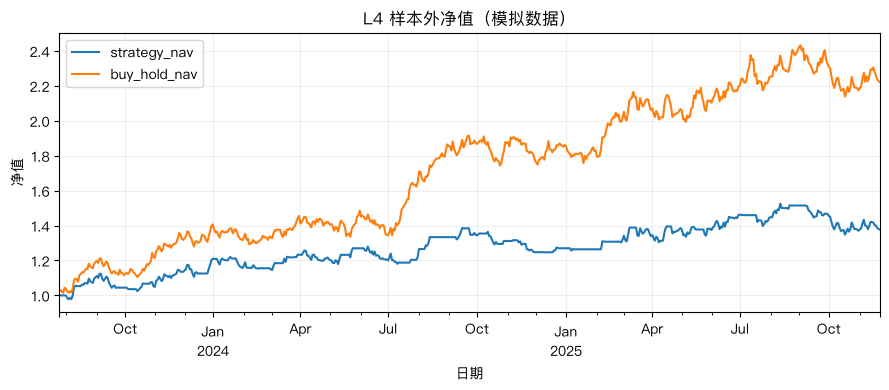

In [6]:
# 汇总模型、风险和归因指标，并保存图表。
metrics = pd.Series({
    "accuracy": accuracy_score(evaluation["label"], evaluation["prediction"]),
    "balanced_accuracy": balanced_accuracy_score(evaluation["label"], evaluation["prediction"]),
    "positive_rate": evaluation["label"].mean(),
    "strategy_return": evaluation["strategy_nav"].iloc[-1] - 1,
    "buy_hold_return": evaluation["buy_hold_nav"].iloc[-1] - 1,
    "empirical_1pct": tail["1%_quantile"],
    "market_beta": factor["market_beta"],
})
metrics_path = OUTPUT_DIR / "L4_model_metrics.csv"
metrics.to_frame("value").to_csv(metrics_path)
display(metrics.to_frame("value"))

axis = evaluation[["strategy_nav", "buy_hold_nav"]].plot(
    figsize=(9, 4), title="L4 样本外净值（模拟数据）"
)
axis.set(xlabel="日期", ylabel="净值")
axis.grid(alpha=0.2)
axis.figure.tight_layout()
chart_path = OUTPUT_DIR / "L4_oof_nav.png"
axis.figure.savefig(chart_path, dpi=150)
plt.show()
assert metrics_path.exists() and chart_path.exists()

## 方法边界与复用结论


- 本实验用于验证防泄漏流程，不追求得到正收益。
- 因子模型是区间归因，分类模型是条件预测，两者不能混为因果结论。
- 真实策略还需多标的、跨时期、概率校准、容量、滑点和置信区间。


本课代码验证的是方法和数据契约，不是未来收益。迁移到真实研究前，还需重新核对来源授权、复权、时区、可得时间、交易成本和样本外边界。